# Markowitz Portfolio Optimization
**Dimitar Zhelezov**, Master's in Mathematical Modelling in Economics, FMI, SU

## 1. Introduction

How should an investor split their money between several assets? In 1952, Harry Markowitz answered this question by treating it as a mathematical optimization problem: investors want high expected return and low risk, and these two goals pull against each other. For every target level of return, there is exactly one portfolio with the lowest possible risk. The set of all such portfolios forms the *efficient frontier*, and Markowitz's work became the foundation of modern portfolio theory.

In this project, I shall derive the efficient frontier mathematically and then compute it in Python on real market data (10 assets). I will operate within the scope of the course material (linear algebra, calculus, probability and statistics) and introduce two new concepts: **Lagrange multipliers** (optimization with constraints) and the **matrix inverse**.

The notebook is organized as follows:

1. Introduction and assumptions
2. Setting up the problem
3. Why diversification works
4. The optimization problem
5. New concept: the matrix inverse
6. New concept: Lagrange multipliers
7. The global minimum-variance portfolio
8. The efficient frontier
9. Application to real data
10. Conclusion

### Assumptions
- An investor cares only about the expected return and the risk (variance) of the portfolio.
- There is a single investment period: the investor chooses weights once and holds them.
- Expected returns and covariances are known. In practice they are estimated from historical data.
- There are no transaction costs or taxes, and assets can be bought in any fraction.
- Every asset carries some risk, and no asset's returns are an exact combination of the others' (mathematically: the covariance matrix is invertible).
- Short selling is allowed (weights may be negative).
- A portfolio holds at least 2 assets.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf #I use Yahoo Finance to get my data. The data consists of 10 assets. This library allows #direct access to much financial data

## 2. Setting up the problem

Let $P_{i,t}$ denote the price of asset $i$ at time $t$. The return of asset $i$ over one period is

$$
R_{i,t} = \frac{P_{i,t} - P_{i,t-1}}{P_{i,t-1}}.
$$

Before it is realized, the return is a random variable. An investor splits their wealth across $n$ assets, putting a fraction $w_i$ (the *weight*) into asset $i$, with all weights summing to one:

$$
\sum_{i=1}^{n} w_i = 1 \quad \Longleftrightarrow \quad \mathbf{1}^\top w = 1,
$$

where $\mathbf{1} = (1, \ldots, 1)^\top$ is a vector of ones. Since short selling is allowed, individual weights may be negative or larger than one. This is called the *budget constraint* (it will enter the optimization problem later).

The portfolio return is the weighted sum of the asset returns:

$$
R_p = \sum_{i=1}^{n} w_i R_i = w^\top R,
$$

where $w = (w_1, \ldots, w_n)^\top$ is the vector of weights and $R = (R_1, \ldots, R_n)^\top$ is the random vector of returns (they are random, since they are forward looking).

By linearity of expectation, the expected portfolio return is

$$
\mathbb{E}[R_p] = \mu_p = \sum_{i=1}^{n} w_i \, \mathbb{E}[R_i] = w^\top \mu,
$$

where $\mu = (\mu_1, \ldots, \mu_n)^\top$ is the vector of expected returns.

The risk of a portfolio is measured by the variance of its return. Unlike the expected return, it depends not only on each asset's own variance but also on how the assets move together (their covariances):

$$
\sigma_p^2 = \operatorname{Var}(R_p) = \sum_{i=1}^{n}\sum_{j=1}^{n} w_i w_j \sigma_{ij} = w^\top \Sigma w,
$$

where $\Sigma$ is the covariance matrix of returns, with entries $\sigma_{ij} = \operatorname{Cov}(R_i, R_j)$ and $\sigma_{ii} = \sigma_i^2$. The double sum follows from the bilinearity of covariance: $\operatorname{Var}\left(\sum_i w_i R_i\right) = \sum_i \sum_j w_i w_j \operatorname{Cov}(R_i, R_j)$.

The square root $\sigma_p$ (the standard deviation, or *volatility*) is in the same units as returns, so it is what I plot.

## 3. Why diversification works

### 3.1 Two assets

Take two assets with weights $w$ and $1 - w$. Writing the double sum out by hand,

$$
\sigma_p^2(w) = w^2 \sigma_1^2 + (1-w)^2 \sigma_2^2 + 2w(1-w)\sigma_{12},
$$

where $\sigma_{12} = \rho \, \sigma_1 \sigma_2$ and $\rho$ is the correlation between the two assets. Three cases show what correlation does:

- If $\rho = 1$, then $\sigma_p = w\sigma_1 + (1-w)\sigma_2$: the risk is just the weighted average of the two risks, and mixing the assets brings no benefit.
- If $\rho < 1$, then $\sigma_p$ is *strictly smaller* than that weighted average. This is the benefit of diversification.
- If $\rho = -1$, the two assets move in exactly opposite directions, and some value of $w$ removes all risk.

Because $\sigma_p^2(w)$ is a quadratic polynomial in $w$, we can find the lowest-risk mix with one derivative:

$$
\frac{d\sigma_p^2}{dw} = 2w\sigma_1^2 - 2(1-w)\sigma_2^2 + 2(1-2w)\sigma_{12} = 0
\quad \Longrightarrow \quad
w^* = \frac{\sigma_2^2 - \sigma_{12}}{\sigma_1^2 + \sigma_2^2 - 2\sigma_{12}}.
$$

The second derivative is

$$
\frac{d^2\sigma_p^2}{dw^2} = 2\left(\sigma_1^2 + \sigma_2^2 - 2\sigma_{12}\right) = 2\operatorname{Var}(R_1 - R_2) > 0,
$$

so the function is convex and $w^*$ is a minimum.

**Example:**

Bonds with $\sigma_1 = 5\%$ and stocks with $\sigma_2 = 15\%$, correlation $\rho = 0.2$, so $\sigma_{12} = 0.2 \cdot 0.05 \cdot 0.15 = 0.0015$:

$$
w^* = \frac{0.0225 - 0.0015}{0.0025 + 0.0225 - 2(0.0015)} = \frac{0.021}{0.022} \approx 0.9545,
\qquad \sigma_p \approx 4.95\%.
$$

Adding about 4.5% of an asset that is *three times as risky* makes the portfolio *less* risky than bonds alone.

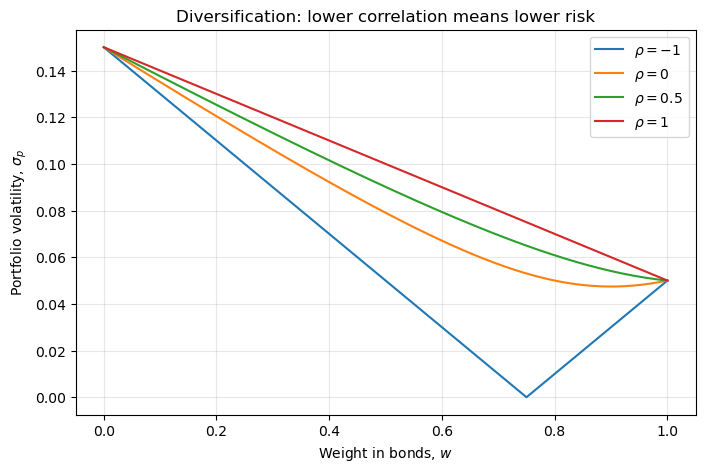

In [ ]:
sigma1 = 0.05
sigma2 = 0.15

#I am going to define the volatility as a function, then plot it, to demonstrate the effects of various correlations (-1, 0, 0.5, 1)
def portfolio_volatility(w, rho):
    cov12 = rho*sigma1*sigma2
    st_dev = np.sqrt(w**2*sigma1**2 + (1 - w)**2*sigma2**2 + 2*w*(1 - w)*cov12)
    return st_dev

#linspace creates an array which gives equal space between each value, resulting in a grid of 201 weights from 0 to 1
w = np.linspace(0, 1, 201)

#I compute and draw one curve per correlation
fig, ax = plt.subplots(figsize=(8, 5))
for rho in [-1, 0, 0.5, 1]:
    ax.plot(w, portfolio_volatility(w, rho), label=rf"$\rho = {rho}$")

ax.set_xlabel(r"Weight in bonds, $w$")
ax.set_ylabel(r"Portfolio volatility, $\sigma_p$")
ax.set_title("Diversification: lower correlation means lower risk")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 3.2 Many assets

Now let's take $n$ assets and invest equally in each, so $w_i = \frac{1}{n}$ for every $i$. We start from the general formula for portfolio variance from Section 2:

$$
\sigma_p^2 = \sum_{i=1}^{n}\sum_{j=1}^{n} w_i w_j \sigma_{ij}.
$$

Every product $w_i w_j$ equals $\frac{1}{n} \cdot \frac{1}{n} = \frac{1}{n^2}$, which does not depend on $i$ or $j$, so it moves outside the sums:

$$
\sigma_p^2 = \frac{1}{n^2}\sum_{i=1}^{n}\sum_{j=1}^{n} \sigma_{ij}.
$$

The double sum adds up every entry of the covariance matrix $\Sigma$. Its entries are of two kinds:

- **Diagonal entries** ($i = j$): these are the variances, $\sigma_{ii} = \sigma_i^2$. There are $n$ of them.
- **Off-diagonal entries** ($i \neq j$): these are the covariances between *different* assets. There are $n^2 - n = n(n-1)$ of them, because we subrtact the number of diagonal entries $n$ from the total number of entries $n^2$.

For example, with $n = 3$:

$$
\Sigma = \begin{pmatrix}
\color{blue}{\sigma_1^2} & \sigma_{12} & \sigma_{13} \\
\sigma_{21} & \color{blue}{\sigma_2^2} & \sigma_{23} \\
\sigma_{31} & \sigma_{32} & \color{blue}{\sigma_3^2}
\end{pmatrix},
\qquad \text{3 variances (blue) and } 3 \cdot 2 = 6 \text{ covariances.}
$$

So the double sum can be written as

$$
\sigma_p^2 = \frac{1}{n^2}\sum_{i=1}^{n} \sigma_i^2 + \frac{1}{n^2}\sum_{i \neq j} \sigma_{ij}.
$$

Let

$$
\bar{\sigma}^2 = \frac{1}{n}\sum_{i=1}^{n} \sigma_i^2
\qquad \text{and} \qquad
\bar{c} = \frac{1}{n(n-1)}\sum_{i \neq j} \sigma_{ij}.
$$

$\bar{\sigma}^2$ is the **average variance** of the individual assets (the sum of the $n$ variances, divided by how many there are). $\bar{c}$ is the **average covariance** between two different assets (the sum of the $n(n-1)$ off-diagonal entries, divided by how many there are). Rearranging these definitions gives

$$
\sum_{i=1}^{n} \sigma_i^2 = n\,\bar{\sigma}^2
\qquad \text{and} \qquad
\sum_{i \neq j} \sigma_{ij} = n(n-1)\,\bar{c}.
$$



$$
\begin{aligned}
\sigma_p^2 &= \frac{1}{n^2} \cdot n\,\bar{\sigma}^2 + \frac{1}{n^2} \cdot n(n-1)\,\bar{c} \\
&= \frac{1}{n}\,\bar{\sigma}^2 + \frac{n-1}{n}\,\bar{c}.
\end{aligned}
$$

Assume the average variance and average covariance stay roughly stable as we add assets. As $n \to \infty$:

- $\frac{1}{n} \to 0$, so the first term $\frac{1}{n}\bar{\sigma}^2$ vanishes;
- $\frac{n-1}{n} = 1 - \frac{1}{n} \to 1$, so the second term approaches $\bar{c}$.

Therefore

$$
\sigma_p^2 \;\xrightarrow{\;n \to \infty\;}\; \bar{c}.
$$

The first term is **idiosyncratic risk**: risk specific to individual companies (a failed product, a lawsuit), which averages out across many assets. The second term is **systematic risk**: risk that assets share because they move together (recessions, interest-rate changes). No amount of diversification removes it. A well-diversified portfolio is left with roughly the average covariance of its assets.

**Example.** 

Suppose every asset has volatility $30\%$ (so $\bar{\sigma}^2 = 0.09$) and every pair has correlation $0.3$, so $\bar{c} = 0.3 \cdot 0.3 \cdot 0.3 = 0.027$. A single asset has volatility $30\%$, but a large equal-weight portfolio approaches $\sqrt{0.027} \approx 16.4\%$. Diversification removes almost half the risk, but no more.